In [ ]:

!pip -q install xgboost lightgbm shap

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import warnings
warnings.filterwarnings("ignore")

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import lightgbm as lgb
import shap

uploaded = files.upload()
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


Saving placement_predict_50k Dataset.csv to placement_predict_50k Dataset.csv
Dataset loaded successfully!
Shape: (50000, 32)
Columns: ['StudentID', 'Gender', 'City', 'CollegeTier', 'Stream', 'Specialisation', 'Hostel', 'HistoryOfBacklogs', 'SGPA_Sem1', 'SGPA_Sem2', 'SGPA_Sem3', 'SGPA_Sem4', 'SGPA_Sem5', 'SGPA_Sem6', 'SGPA_Sem7', 'SGPA_Sem8', 'CGPA', 'AttendancePercent', 'Internships', 'Projects', 'Workshops', 'Certifications', 'Publications', 'AptitudeTestScore', 'SoftSkillsRating', 'CodingTestScore', 'MockInterviewScore', 'ExtraCurricular', 'CGPA_Tier', 'PlacementStatus', 'IsAnomaly', 'Salary Package']


,StudentID,Gender,City,CollegeTier,Stream,Specialisation,Hostel,HistoryOfBacklogs,SGPA_Sem1,SGPA_Sem2,...,Publications,AptitudeTestScore,SoftSkillsRating,CodingTestScore,MockInterviewScore,ExtraCurricular,CGPA_Tier,PlacementStatus,IsAnomaly,Salary Package
0,1,Male,Ahmedabad,Tier2,ECE,Networking,No,No,6.02,6.54,...,0,66.7,2.2,49.4,47.8,0,Low,0,0,0.00
1,2,Female,Mumbai,Tier2,ECE,DataScience,Yes,Yes,5.84,5.12,...,0,48.2,2.4,26.7,25.8,0,Low,0,0,0.00
2,3,Male,Kolkata,Tier2,IT,DataScience,Yes,No,4.91,5.29,...,0,73.8,2.8,67.7,41.5,0,Low,1,0,3.89
3,4,Male,Jaipur,Tier1,CS,AI,No,No,7.67,8.03,...,0,69.8,2.7,66.9,48.0,0,Mid,1,0,8.37
4,5,Male,Pune,Tier2,IT,DataScience,Yes,No,8.14,8.97,...,1,73.1,2.1,71.7,61.7,1,High,1,0,18.99


In [ ]:

X = df.drop(columns=["PlacementStatus", "CGPA_Tier"])
y = df["PlacementStatus"]

# Encode target labels if they are text
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
y = pd.Series(label_encoder.fit_transform(y), index=y.index)

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

feature_names = preprocessor.get_feature_names_out()

print("Preprocessing completed!")
print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)


Preprocessing completed!
Training shape: (40000, 52)
Validation shape: (10000, 52)


In [ ]:

def boosting_benchmark(X_train, y_train, X_val, y_val):
    results = []
    models = {}

    # AdaBoost
    models["AdaBoost"] = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1),
        n_estimators=100,
        learning_rate=0.5,
        random_state=42
    )

    # Gradient Boosting
    models["GBC"] = GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )

    # XGBoost with early stopping
    models["XGB"] = XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        objective="binary:logistic",
        eval_metric="logloss",
        early_stopping_rounds=20,
        random_state=42,
        n_jobs=-1
    )

    # LightGBM with early stopping
    models["LGB"] = LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        verbosity=-1,
        random_state=42,
        n_jobs=-1
    )

    fitted_models = {}

    for name, model in models.items():
        start = time.time()

        if name == "XGB":
            model.fit(
                X_train, y_train,
                eval_set=[(X_val, y_val)],
                verbose=False
            )

        elif name == "LGB":
            model.fit(
                X_train, y_train,
                eval_set=[(X_val, y_val)],
                callbacks=[
                    lgb.early_stopping(20, verbose=False),
                    lgb.log_evaluation(0)
                ]
            )

        else:
            model.fit(X_train, y_train)

        elapsed = time.time() - start
        val_accuracy = accuracy_score(
            y_val, model.predict(X_val)
        )

        results.append({
            "Model": name,
            "val_accuracy": val_accuracy,
            "training_time_sec": elapsed
        })

        fitted_models[name] = model

        print(
            f"{name}: validation accuracy = {val_accuracy:.4f}, "
            f"time = {elapsed:.2f} seconds"
        )

    results_df = pd.DataFrame(results)
    results_df = results_df.sort_values(
        "val_accuracy", ascending=False
    ).reset_index(drop=True)

    return results_df, fitted_models


In [ ]:

benchmark_df, fitted_models = boosting_benchmark(
    X_train_processed,
    y_train,
    X_val_processed,
    y_val
)

print("Boosting Benchmark Results:")
display(benchmark_df.round(4))


AdaBoost: validation accuracy = 0.9983, time = 15.14 seconds
GBC: validation accuracy = 0.9983, time = 20.26 seconds
XGB: validation accuracy = 0.9982, time = 3.11 seconds
LGB: validation accuracy = 0.9983, time = 2.14 seconds
Boosting Benchmark Results:


,Model,val_accuracy,training_time_sec
0,AdaBoost,0.9983,15.1397
1,GBC,0.9983,20.2582
2,LGB,0.9983,2.1373
3,XGB,0.9982,3.1149


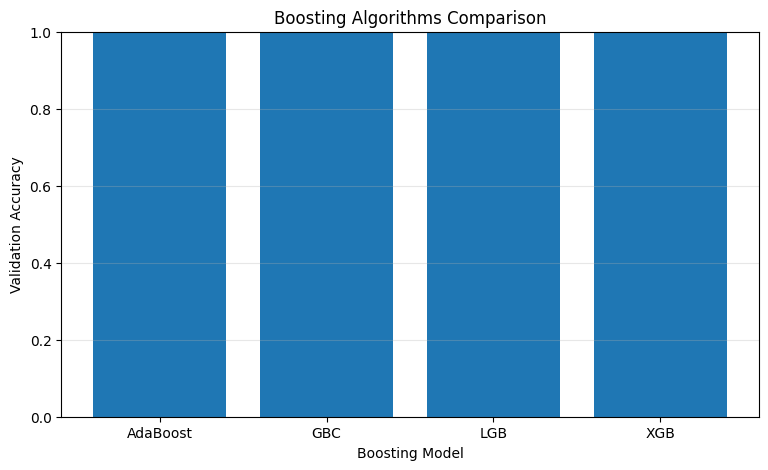

In [ ]:

plt.figure(figsize=(9, 5))

plt.bar(
    benchmark_df["Model"],
    benchmark_df["val_accuracy"]
)

plt.xlabel("Boosting Model")
plt.ylabel("Validation Accuracy")
plt.title("Boosting Algorithms Comparison")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.show()


,Estimator,Estimator_Weight
0,1,3.341680
1,2,1.670840
2,3,0.835420
3,4,0.521392
4,5,0.589545
5,6,0.483338
6,7,0.540459
7,8,0.250636
8,9,0.585373
9,10,0.241511


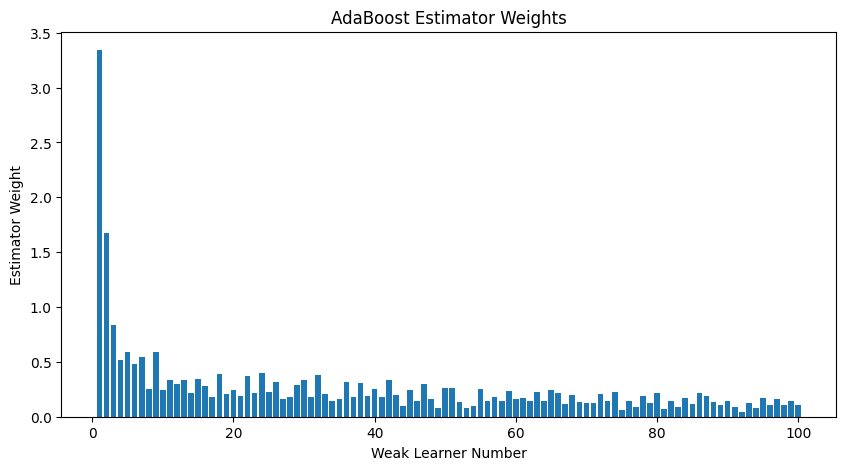

In [ ]:

ada_model = fitted_models["AdaBoost"]

weights_df = pd.DataFrame({
    "Estimator": range(1, len(ada_model.estimator_weights_) + 1),
    "Estimator_Weight": ada_model.estimator_weights_
})

display(weights_df.head(15))

plt.figure(figsize=(10, 5))
plt.bar(
    weights_df["Estimator"],
    weights_df["Estimator_Weight"]
)
plt.xlabel("Weak Learner Number")
plt.ylabel("Estimator Weight")
plt.title("AdaBoost Estimator Weights")
plt.show()


In [ ]:

xgb_model = fitted_models["XGB"]
lgb_model = fitted_models["LGB"]

print("XGBoost best iteration:",
      getattr(xgb_model, "best_iteration", "Not available"))

print("LightGBM best iteration:",
      getattr(lgb_model, "best_iteration_", "Not available"))

print("XGBoost and LightGBM early-stopping comparison completed.")


XGBoost best iteration: 203
LightGBM best iteration: 131
XGBoost and LightGBM early-stopping comparison completed.


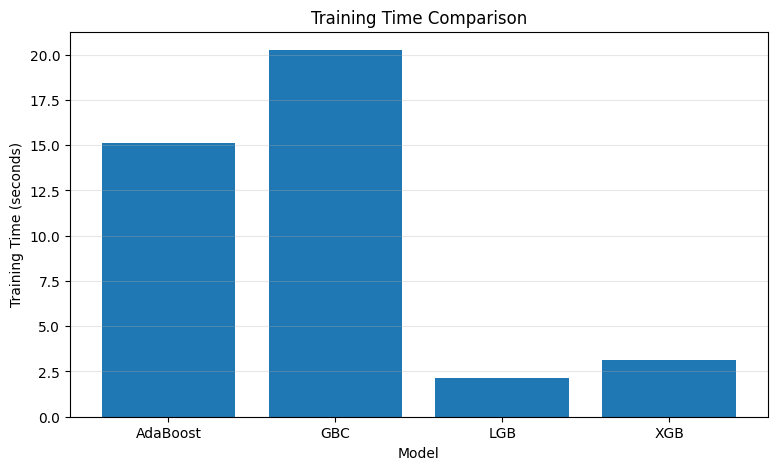

Fastest model:
Model                     LGB
training_time_sec    2.137299
Name: 2, dtype: object


In [ ]:

plt.figure(figsize=(9, 5))

plt.bar(
    benchmark_df["Model"],
    benchmark_df["training_time_sec"]
)

plt.xlabel("Model")
plt.ylabel("Training Time (seconds)")
plt.title("Training Time Comparison")
plt.grid(axis="y", alpha=0.3)
plt.show()

print("Fastest model:")
print(
    benchmark_df.loc[
        benchmark_df["training_time_sec"].idxmin(),
        ["Model", "training_time_sec"]
    ]
)


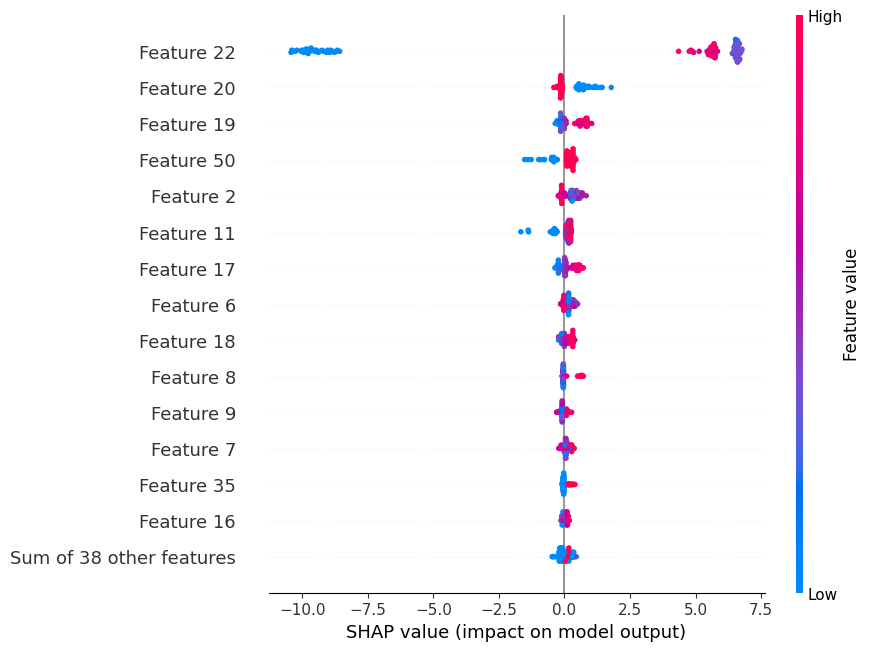

In [ ]:

xgb_model = fitted_models["XGB"]

X_shap = X_val_processed[:min(100, X_val_processed.shape[0])]

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_shap)

shap.plots.beeswarm(
    shap_values,
    max_display=15
)


,Model,Version 1,Version 2
0,AdaBoost,0.9980,0.9983
1,GBC,0.9983,0.9983
2,XGB,0.9982,0.9982
3,LGB,0.9982,0.9983


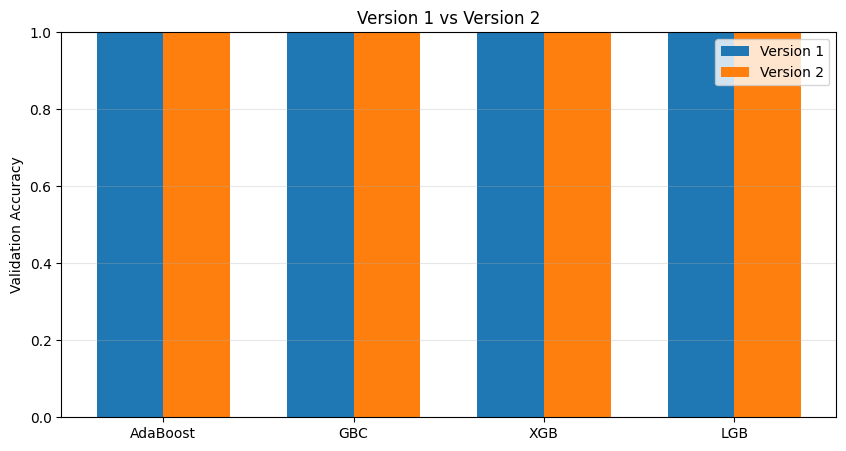

In [ ]:

baseline_models = {
    "AdaBoost": AdaBoostClassifier(
        n_estimators=100, random_state=42
    ),
    "GBC": GradientBoostingClassifier(
        n_estimators=100, random_state=42
    ),
    "XGB": XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.05,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ),
    "LGB": LGBMClassifier(
        n_estimators=100,
        verbosity=-1,
        random_state=42,
        n_jobs=-1
    )
}

v1_accuracy = {}

for name, model in baseline_models.items():
    model.fit(X_train_processed, y_train)
    v1_accuracy[name] = accuracy_score(
        y_val, model.predict(X_val_processed)
    )

v2_accuracy = dict(zip(
    benchmark_df["Model"],
    benchmark_df["val_accuracy"]
))

versions_df = pd.DataFrame({
    "Model": list(baseline_models.keys()),
    "Version 1": [v1_accuracy[m] for m in baseline_models],
    "Version 2": [v2_accuracy[m] for m in baseline_models]
})

display(versions_df.round(4))

x = np.arange(len(versions_df))
width = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x - width/2, versions_df["Version 1"], width, label="Version 1")
plt.bar(x + width/2, versions_df["Version 2"], width, label="Version 2")

plt.xticks(x, versions_df["Model"])
plt.ylabel("Validation Accuracy")
plt.title("Version 1 vs Version 2")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()
